In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

torch.manual_seed(42) # usning a randome seed for reproducibility

tokens = ["Cat","hate","Mouse"] #input token and basic dimention
seq_len = len(tokens)

d_model = 16
d_k = 8
d_v = 8

embeddings = torch.randn(seq_len, d_model)
print("Input Embeddings (Hidden States):")
for token, emb in zip(tokens, embeddings):
    print(f"{token}: {emb[:4].tolist()}... (dimension: {d_model})")

Input Embeddings (Hidden States):
Cat: [1.9269152879714966, 1.4872840642929077, 0.9007171988487244, -2.1055209636688232]... (dimension: 16)
hate: [1.6423169374465942, -0.1595974713563919, -0.4973975419998169, 0.439589262008667]... (dimension: 16)
Mouse: [-1.3846737146377563, -0.8712361454963684, -0.223365917801857, 1.7173614501953125]... (dimension: 16)


In [4]:
# 3. Define projection weights
W_q = torch.randn(d_model, d_k)
W_k = torch.randn(d_model, d_k)
W_v = torch.randn(d_model, d_v)

# Compute Q, K, V
Q = torch.matmul(embeddings, W_q)
K = torch.matmul(embeddings, W_k)
V = torch.matmul(embeddings, W_v)

print("Queries (Q) Shape:", Q.shape)
print("Keys (K) Shape:", K.shape)
print("Values (V) Shape:", V.shape)

Queries (Q) Shape: torch.Size([3, 8])
Keys (K) Shape: torch.Size([3, 8])
Values (V) Shape: torch.Size([3, 8])


In [6]:
# 4. Raw Attention Scores (Q * K^T)
attn_scores = torch.matmul(Q, K.transpose(0, 1))

# 5. Attention Distribution (Softmax)
attn_distribution = F.softmax(attn_scores, dim=-1)

print("Attention Scores:\n", attn_scores.numpy())
print("\nAttention Distribution (Softmax weights):\n", attn_distribution.numpy())

Attention Scores:
 [[-12.674143   26.814388   53.413815 ]
 [  2.502197  -11.91622    -2.7958689]
 [-10.383459  -15.178708  -37.039967 ]]

Attention Distribution (Softmax weights):
 [[1.9877601e-29 2.8055366e-12 1.0000000e+00]
 [9.9502301e-01 5.4449538e-07 4.9763652e-03]
 [9.9179888e-01 8.2011251e-03 2.6281462e-12]]


Text(45.722222222222214, 0.5, 'Queries (Target Tokens)')

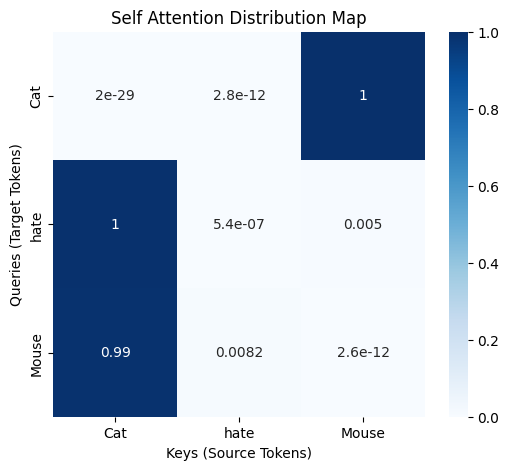

In [7]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    attn_distribution.detach().numpy(),
    annot=True,
    xticklabels=tokens,
    yticklabels=tokens,
    cmap="Blues",
    cbar=True,
    vmin=0,
    vmax=1
)

plt.title("Self Attention Distribution Map")
plt.xlabel("Keys (Source Tokens)")
plt.ylabel("Queries (Target Tokens)")

In [8]:
# Explicitly show the math for step by step computation

for i, q_token in enumerate(tokens):
  print(f"\n--- Calculation for Query token: '{q_token.strip()}' ----")
  q_vec = Q[i]

  raw_scores = []
  scaled_scores = []

  for j, k_token in enumerate(tokens):
    k_vec = K[j]
    dot_prod = torch.dot(q_vec, k_vec).item()
    # Standard scaling factor for transformer attention is sqrt(d_k)
    scaled_prod = dot_prod / np.sqrt(d_k)

    raw_scores.append(dot_prod)
    scaled_scores.append(scaled_prod)

    print(f"  Key '{k_token.strip()}': Raw Score = {dot_prod:.4f}, Scaled Score = {scaled_prod:.4f}")

  # Compute manual Softmax
  exp_scores = np.exp(scaled_scores)
  sum_exp = np.sum(exp_scores)
  probabilities = exp_scores / sum_exp

  print(f"  Softmax Distribution:")
  for j, k_token in enumerate(tokens):
    print(f"    to '{k_token.strip()}': {probabilities[j]:.4f}")


--- Calculation for Query token: 'Cat' ----
  Key 'Cat': Raw Score = -12.6741, Scaled Score = -4.4810
  Key 'hate': Raw Score = 26.8144, Scaled Score = 9.4803
  Key 'Mouse': Raw Score = 53.4138, Scaled Score = 18.8846
  Softmax Distribution:
    to 'Cat': 0.0000
    to 'hate': 0.0001
    to 'Mouse': 0.9999

--- Calculation for Query token: 'hate' ----
  Key 'Cat': Raw Score = 2.5022, Scaled Score = 0.8847
  Key 'hate': Raw Score = -11.9162, Scaled Score = -4.2130
  Key 'Mouse': Raw Score = -2.7959, Scaled Score = -0.9885
  Softmax Distribution:
    to 'Cat': 0.8623
    to 'hate': 0.0053
    to 'Mouse': 0.1325

--- Calculation for Query token: 'Mouse' ----
  Key 'Cat': Raw Score = -10.3835, Scaled Score = -3.6711
  Key 'hate': Raw Score = -15.1787, Scaled Score = -5.3665
  Key 'Mouse': Raw Score = -37.0400, Scaled Score = -13.0956
  Softmax Distribution:
    to 'Cat': 0.8449
    to 'hate': 0.1551
    to 'Mouse': 0.0001


In [9]:
num_heads = 2

d_k_head = d_model // num_heads
d_v_head = d_model // num_heads

print(f"Embedding dimension (d_model): {d_model}")
print(f"Head dimension (d_k): {d_k_head}")
print(f"Head dimension (d_v): {d_v_head}")

Embedding dimension (d_model): 16
Head dimension (d_k): 8
Head dimension (d_v): 8


In [10]:
# Initialize MHA weights
W_q_mha = torch.randn(d_model, d_model)  # Projecting to all heads combined
W_k_mha = torch.randn(d_model, d_model)
W_v_mha = torch.randn(d_model, d_model)
W_o = torch.randn(d_model, d_model)      # Final output projection weight

# Step 1: Linear projections
Q_mha = torch.matmul(embeddings, W_q_mha)
K_mha = torch.matmul(embeddings, W_k_mha)
V_mha = torch.matmul(embeddings, W_v_mha)

# Step 2: Reshape to split into heads
# New shape: [seq_len, num_heads, d_k_head]
Q_split = Q_mha.view(seq_len, num_heads, d_k_head).transpose(0, 1)
K_split = K_mha.view(seq_len, num_heads, d_k_head).transpose(0, 1)
V_split = V_mha.view(seq_len, num_heads, d_v_head).transpose(0, 1)

print("Split Queries Shape (num_heads, seq_len, d_k_head):", Q_split.shape)
print("Split Keys Shape (num_heads, seq_len, d_k_head):", K_split.shape)
print("Split Values Shape (num_heads, seq_len, d_v_head):", V_split.shape)
# Step 3: Compute attention scores and distribution for each head independently

scores = torch.matmul(Q_split, K_split.transpose(-2, -1)) / (d_k_head ** 0.5)
distributions = F.softmax(scores, dim=-1)
head_outputs = torch.matmul(distributions, V_split)

# Step 4: Concatenate head outputs
# Transpose back to [seq_len, num_heads, d_v_head] and flatten the last two dimensions
concat_output = head_outputs.transpose(0, 1).contiguous().view(seq_len, d_model)

# Step 5: Final output projection
final_output = torch.matmul(concat_output, W_o)

print("Attention Distribution Shape (for all heads):", distributions.shape)
print("Concatenated Output Shape:", concat_output.shape)
print("Final Multi-head Attention Output Shape:", final_output.shape)

Split Queries Shape (num_heads, seq_len, d_k_head): torch.Size([2, 3, 8])
Split Keys Shape (num_heads, seq_len, d_k_head): torch.Size([2, 3, 8])
Split Values Shape (num_heads, seq_len, d_v_head): torch.Size([2, 3, 8])
Attention Distribution Shape (for all heads): torch.Size([2, 3, 3])
Concatenated Output Shape: torch.Size([3, 16])
Final Multi-head Attention Output Shape: torch.Size([3, 16])


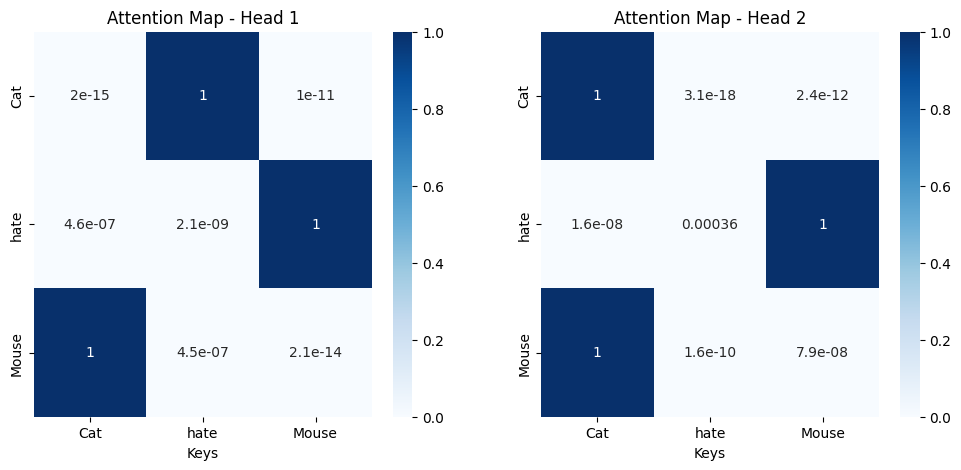

In [11]:
# Let's visualize the attention maps for both heads side-by-side
fig, axes = plt.subplots(1, num_heads, figsize=(12, 5))

for h in range(num_heads):
    sns.heatmap(
        distributions[h].detach().numpy(),
        annot=True,
        xticklabels=tokens,
        yticklabels=tokens,
        cmap="Blues",
        cbar=True,
        vmin=0,
        vmax=1,
        ax=axes[h]
    )
    axes[h].set_title(f"Attention Map - Head {h+1}")
    axes[h].set_xlabel("Keys")